In [1]:
import torch

print(torch.cuda.is_available())

True


In [2]:
!pip install -q ultralytics

In [5]:
import zipfile

zip_path = "/content/human-detection-ae.zip"

with zipfile.ZipFile(zip_path, 'r') as file:
    file.extractall("/content/dataset")

In [6]:
import os
import pandas as pd

print(os.listdir("/content/dataset"))

['test_images', 'sample_submission.csv']


In [7]:
images_path = "/content/dataset/test_images"

images = [
    f for f in os.listdir(images_path)
    if f.lower().endswith(".jpg")
]

print("Number of images:", len(images))

Number of images: 0


In [8]:
sample = pd.read_csv(
    "/content/dataset/sample_submission.csv"
)

print(sample.shape)
print(sample.head())

(590, 2)
     image_id                            PredictionString
0  test_00001  0 0.95 0.500000 0.500000 0.200000 0.400000
1  test_00002                                         NaN
2  test_00003                                         NaN
3  test_00004                                         NaN
4  test_00005                                         NaN


In [9]:
from ultralytics import YOLO

model = YOLO("yolo11m.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [10]:
print(model.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [11]:
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    classes=[0],
    conf=0.25,
    iou=0.45,
    imgsz=640,
    device=0
)


image 1/1 /content/bus.jpg: 640x480 4 persons, 29.2ms
Speed: 93.9ms preprocess, 29.2ms inference, 80.7ms postprocess per image at shape (1, 3, 640, 480)


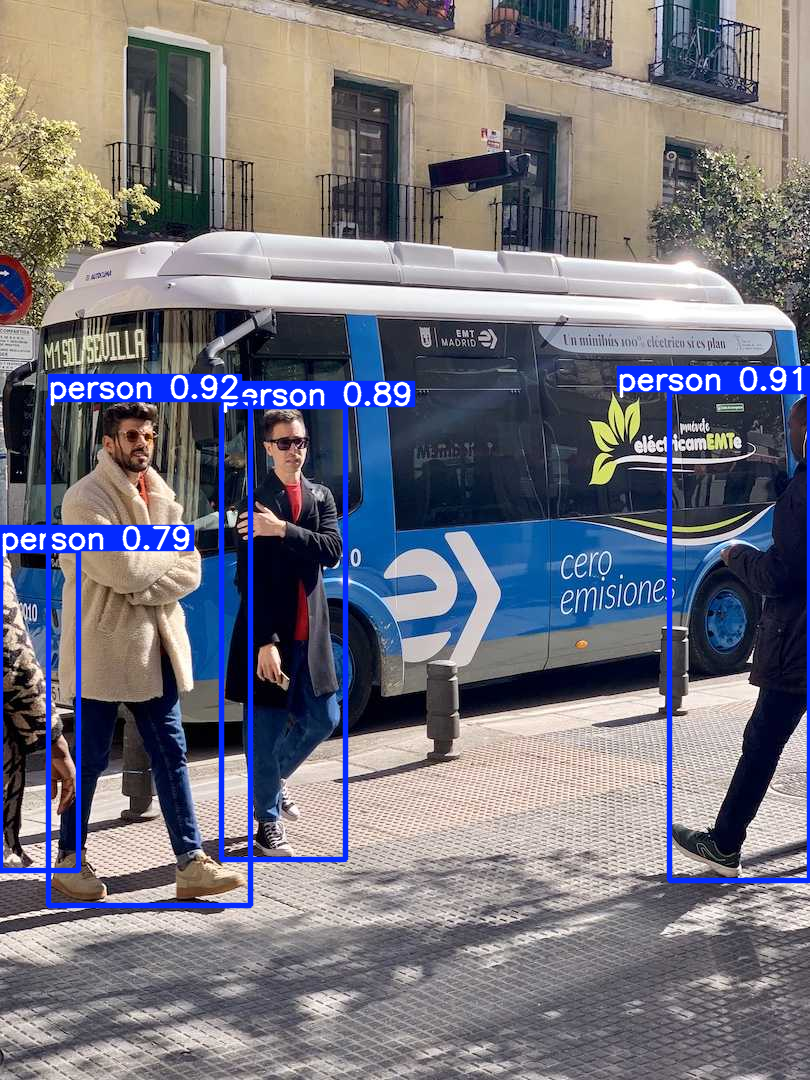

In [12]:
from google.colab.patches import cv2_imshow

cv2_imshow(results[0].plot())

In [13]:
print("Bounding Boxes:")
print(results[0].boxes.xywhn)

print("Confidence Scores:")
print(results[0].boxes.conf)

print("Class IDs:")
print(results[0].boxes.cls)

Bounding Boxes:
tensor([[0.1843, 0.6041, 0.2488, 0.4684],
        [0.9128, 0.5889, 0.1735, 0.4529],
        [0.3502, 0.5865, 0.1530, 0.4196],
        [0.0487, 0.6579, 0.0968, 0.2955]], device='cuda:0')
Confidence Scores:
tensor([0.9163, 0.9072, 0.8935, 0.7869], device='cuda:0')
Class IDs:
tensor([0., 0., 0., 0.], device='cuda:0')


In [15]:
import os

for root, dirs, files in os.walk("/content/dataset"):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Sample files:", files[:5])
    print()

Folder: /content/dataset
Number of files: 1
Sample files: ['sample_submission.csv']

Folder: /content/dataset/test_images
Number of files: 0
Sample files: []

Folder: /content/dataset/test_images/test_images
Number of files: 605
Sample files: ['test_00585.jpg', 'test_00045.jpg', 'test_00440.jpg', 'test_00076.jpg', 'test_00518.jpg']



In [16]:
from pathlib import Path

dataset_dir = Path("/content/dataset")

image_files = [
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in
    [".jpg", ".jpeg", ".png"]
]

image_map = {
    p.stem: str(p)
    for p in image_files
}

image_paths = [
    image_map[image_id]
    for image_id in sample["image_id"]
    if image_id in image_map
]

missing = [
    image_id
    for image_id in sample["image_id"]
    if image_id not in image_map
]

print("Found images:", len(image_files))
print("Required images:", len(sample))
print("Matched images:", len(image_paths))
print("Missing images:", len(missing))

assert len(missing) == 0

Found images: 605
Required images: 590
Matched images: 590
Missing images: 0


In [18]:
import gc
import torch

results = None

gc.collect()
torch.cuda.empty_cache()

In [19]:
import time
from tqdm.auto import tqdm

start = time.time()

predictions = {}

batch_size = 4

for i in tqdm(range(0, len(image_paths), batch_size)):

    batch = image_paths[i:i + batch_size]

    results = model.predict(
        source=batch,
        classes=[0],
        conf=0.25,
        iou=0.45,
        imgsz=640,
        device=0,
        half=True,
        stream=True,
        verbose=False
    )

    for result in results:

        image_id = Path(result.path).stem

        boxes = result.boxes.xywhn.cpu().tolist()
        scores = result.boxes.conf.cpu().tolist()

        predictions[image_id] = list(zip(scores, boxes))

print("Processed images:", len(predictions))
print("Time:", round(time.time() - start, 2), "seconds")

  0%|          | 0/148 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [20]:
print("Processed images:", len(predictions))

Processed images: 590


In [21]:
import numpy as np

counts = [
    len(detections)
    for detections in predictions.values()
]

all_scores = [
    score
    for detections in predictions.values()
    for score, box in detections
]

print("Total images:", len(counts))
print("Total detections:", sum(counts))
print("Images without detections:", counts.count(0))
print("Average detections per image:", np.mean(counts))

if all_scores:
    print("Average confidence:", np.mean(all_scores))

Total images: 590
Total detections: 373
Images without detections: 282
Average detections per image: 0.6322033898305085
Average confidence: 0.5931249214560992


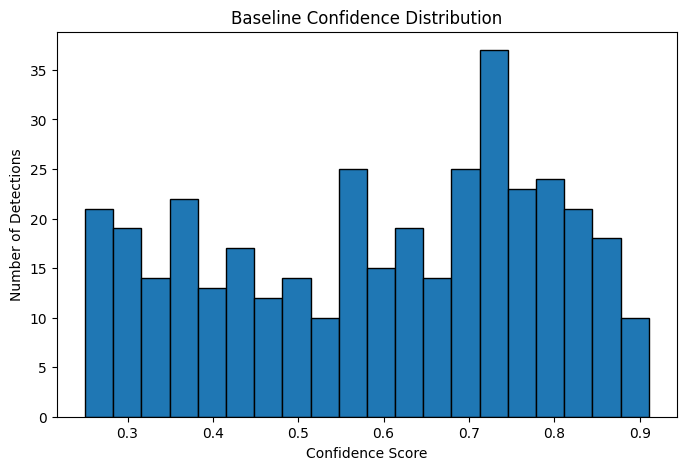

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(all_scores, bins=20, edgecolor="black")

plt.xlabel("Confidence Score")
plt.ylabel("Number of Detections")
plt.title("Baseline Confidence Distribution")

plt.show()

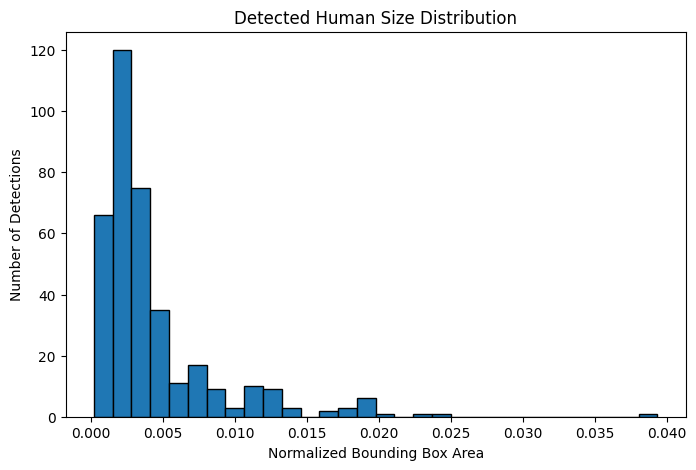

In [23]:
areas = [
    box[2] * box[3]
    for detections in predictions.values()
    for score, box in detections
]

plt.figure(figsize=(8, 5))

plt.hist(areas, bins=30, edgecolor="black")

plt.xlabel("Normalized Bounding Box Area")
plt.ylabel("Number of Detections")
plt.title("Detected Human Size Distribution")

plt.show()

In [24]:
def format_predictions(detections, class_id=1):

    parts = []

    for score, box in detections:

        x, y, w, h = box

        detection = (
            f"{class_id} {score:.6f} "
            f"{x:.6f} {y:.6f} "
            f"{w:.6f} {h:.6f}"
        )

        parts.append(detection)

    return " ".join(parts)

In [25]:
assert set(predictions) == set(sample["image_id"])

submission = sample[["image_id"]].copy()

submission["PredictionString"] = [
    format_predictions(predictions[image_id])
    for image_id in submission["image_id"]
]

print(submission.shape)
print(submission.head())

(590, 2)
     image_id                                PredictionString
0  test_00001  1 0.847656 0.412891 0.202009 0.075781 0.236607
1  test_00002  1 0.830566 0.404785 0.573611 0.074805 0.144444
2  test_00003                                                
3  test_00004                                                
4  test_00005                                                


In [26]:
submission.to_csv(
    "/content/submission_baseline.csv",
    index=False
)

In [27]:
from google.colab import files

files.download("/content/submission_baseline.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
check = pd.read_csv(
    "/content/submission_baseline.csv",
    keep_default_na=False
)

print("Shape:", check.shape)
print("Columns:", check.columns.tolist())
print("Unique IDs:", check["image_id"].nunique())

print("Correct ID ordering:",
      check["image_id"].equals(sample["image_id"]))

print("Invalid prediction strings:",
      sum(len(s.split()) % 6 != 0
          for s in check["PredictionString"]))

print(check.head(10).to_string())

Shape: (590, 2)
Columns: ['image_id', 'PredictionString']
Unique IDs: 590
Correct ID ordering: True
Invalid prediction strings: 0
     image_id                                PredictionString
0  test_00001  1 0.847656 0.412891 0.202009 0.075781 0.236607
1  test_00002  1 0.830566 0.404785 0.573611 0.074805 0.144444
2  test_00003                                                
3  test_00004                                                
4  test_00005                                                
5  test_00006                                                
6  test_00007                                                
7  test_00008                                                
8  test_00009  1 0.455078 0.366797 0.686111 0.044922 0.094444
9  test_00010  1 0.735840 0.584766 0.626389 0.038281 0.058333


In [33]:
submission = submission.copy()

submission["PredictionString"] = (
    submission["PredictionString"]
    .fillna("")
    .replace("", " ")
)

submission.to_csv(
    "/content/submission_baseline.csv",
    index=False
)

In [34]:
check_fixed = pd.read_csv(
    "/content/submission_baseline.csv"
)

print("Null values:")
print(check_fixed.isnull().sum())

print("Shape:", check_fixed.shape)

Null values:
image_id            0
PredictionString    0
dtype: int64
Shape: (590, 2)


In [35]:
from google.colab import files

files.download("/content/submission_baseline.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
def format_predictions(detections, class_id=1):
    parts = []

    for score, box in detections:
        x, y, w, h = box

        parts.append(
            f"{class_id} {x:.6f} {y:.6f} "
            f"{w:.6f} {h:.6f}"
        )

    return " ".join(parts) if parts else " "


submission = sample[["image_id"]].copy()

submission["PredictionString"] = [
    format_predictions(predictions[image_id])
    for image_id in submission["image_id"]
]

submission.to_csv(
    "/content/corrected.csv",
    index=False
)

In [40]:
check = pd.read_csv("/content/corrected.csv")

print("Shape:", check.shape)
print("Null values:", check.isnull().sum().sum())
print("Invalid strings:",
      sum(len(s.split()) % 5 != 0
          for s in check["PredictionString"]))

print(check.head(10))

Shape: (590, 2)
Null values: 0
Invalid strings: 0
     image_id                       PredictionString
0  test_00001  1 0.412891 0.202009 0.075781 0.236607
1  test_00002  1 0.404785 0.573611 0.074805 0.144444
2  test_00003                                       
3  test_00004                                       
4  test_00005                                       
5  test_00006                                       
6  test_00007                                       
7  test_00008                                       
8  test_00009  1 0.366797 0.686111 0.044922 0.094444
9  test_00010  1 0.584766 0.626389 0.038281 0.058333


In [41]:
from google.colab import files

files.download("/content/corrected.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
import json

baseline_predictions = predictions.copy()

with open("/content/E1_predictions.json", "w") as f:
    json.dump(baseline_predictions, f)

In [43]:
import time
from tqdm.auto import tqdm
from pathlib import Path

def run_inference(model, image_paths,
                  imgsz=640,
                  conf=0.25,
                  iou=0.45,
                  batch_size=2):

    start = time.time()
    output = {}

    for i in tqdm(range(0, len(image_paths), batch_size)):

        batch = image_paths[i:i + batch_size]

        results = model.predict(
            source=batch,
            classes=[0],
            conf=conf,
            iou=iou,
            imgsz=imgsz,
            device=0,
            half=True,
            stream=True,
            verbose=False
        )

        for result in results:

            image_id = Path(result.path).stem

            boxes = result.boxes.xywhn.cpu().tolist()
            scores = result.boxes.conf.cpu().tolist()

            output[image_id] = list(zip(scores, boxes))

    elapsed = time.time() - start

    print("Processed images:", len(output))
    print("Runtime:", round(elapsed, 2), "seconds")

    return output

In [44]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

highres_predictions = run_inference(
    model,
    image_paths,
    imgsz=1280,
    conf=0.25,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/295 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [45]:
import numpy as np
import pandas as pd

def summarize(predictions):

    counts = [len(d) for d in predictions.values()]

    scores = [
        score
        for detections in predictions.values()
        for score, box in detections
    ]

    areas = [
        box[2] * box[3]
        for detections in predictions.values()
        for score, box in detections
    ]

    return {
        "Total images": len(counts),
        "Total detections": sum(counts),
        "Empty images": counts.count(0),
        "Mean confidence": np.mean(scores) if scores else 0,
        "Small detections": sum(a < 0.005 for a in areas)
    }


comparison = pd.DataFrame({
    "E1 - 640": summarize(baseline_predictions),
    "E2 - 1280": summarize(highres_predictions)
})

display(comparison)

,E1 - 640,E2 - 1280
Total images,590.000000,590.000000
Total detections,373.000000,421.000000
Empty images,282.000000,249.000000
Mean confidence,0.593125,0.656315
Small detections,290.000000,318.000000


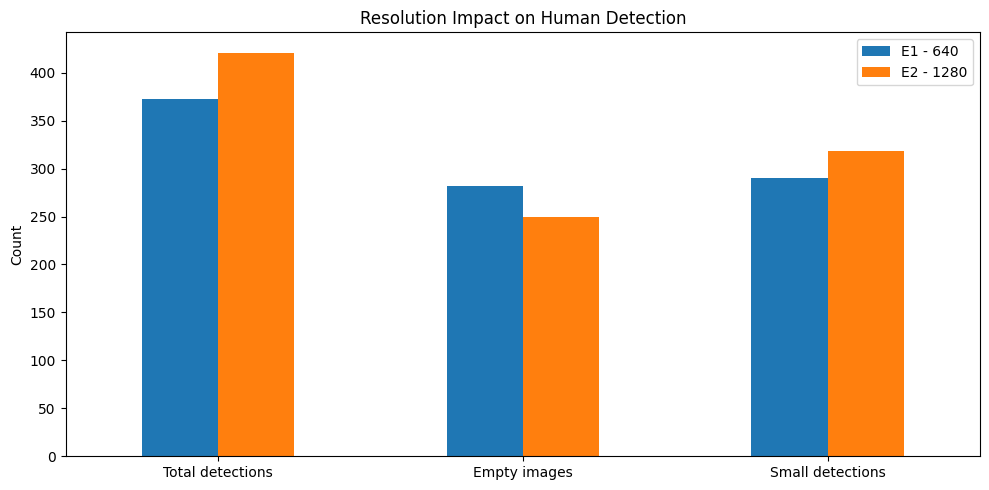

In [46]:
import matplotlib.pyplot as plt

metrics = [
    "Total detections",
    "Empty images",
    "Small detections"
]

comparison.loc[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Resolution Impact on Human Detection")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
with open("/content/E2_predictions.json", "w") as f:
    json.dump(highres_predictions, f)

In [48]:
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip -O /content/visdrone_val.zip

/content/visdrone_v 100%[===================>]  77.86M   138MB/s    in 0.6s    


In [49]:
with zipfile.ZipFile(
    "/content/visdrone_val.zip", "r"
) as file:

    file.extractall("/content/visdrone")

In [50]:
for root, dirs, files in os.walk("/content/visdrone"):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Examples:", files[:3])
    print()

Folder: /content/visdrone
Number of files: 0
Examples: []

Folder: /content/visdrone/VisDrone2019-DET-val
Number of files: 1
Examples: ['.DS_Store']

Folder: /content/visdrone/VisDrone2019-DET-val/annotations
Number of files: 548
Examples: ['0000276_01201_d_0000513.txt', '0000154_01601_d_0000001.txt', '0000069_00483_d_0000002.txt']

Folder: /content/visdrone/VisDrone2019-DET-val/images
Number of files: 548
Examples: ['0000356_02941_d_0000644.jpg', '0000276_00601_d_0000510.jpg', '0000215_02319_d_0000261.jpg']



In [51]:
from pathlib import Path

val_dir = Path("/content/visdrone/VisDrone2019-DET-val")

val_images_dir = val_dir / "images"
val_annotations_dir = val_dir / "annotations"

val_image_paths = sorted(
    str(p) for p in val_images_dir.glob("*.jpg")
)

print("Validation images:", len(val_image_paths))

assert all(
    (val_annotations_dir / (Path(p).stem + ".txt")).exists()
    for p in val_image_paths
)

Validation images: 548


In [52]:
annotation_path = (
    val_annotations_dir /
    (Path(val_image_paths[0]).stem + ".txt")
)

with open(annotation_path) as f:
    print(f.read()[:1500])

871,572,54,92,1,4,0,0
948,592,62,92,1,4,0,0
874,705,67,110,1,4,0,1
971,791,27,54,1,10,0,1
976,794,19,38,1,2,0,1
414,921,48,46,1,10,0,1
447,1054,27,26,1,1,1,0
430,902,27,49,1,1,0,1
405,837,55,52,1,8,0,1
416,856,19,36,1,2,0,1
349,796,60,61,1,8,0,1
378,753,39,44,1,10,0,1
630,722,56,43,1,10,0,1
651,745,93,42,1,7,0,1
488,775,50,58,1,10,0,1
543,781,69,40,1,7,0,1
569,756,49,34,1,10,0,1
571,720,48,31,1,10,0,1
602,684,46,29,1,10,0,1
519,743,45,29,1,10,0,1
518,724,50,27,1,10,0,1
603,652,48,49,1,8,0,1
537,700,56,35,1,10,0,1
536,667,63,58,1,8,0,1
531,625,46,52,1,8,0,1
555,583,45,42,1,8,0,1
567,581,49,38,1,10,0,1
613,599,42,29,1,10,0,1
663,588,43,30,1,10,0,1
637,611,41,27,1,10,0,1
629,630,45,30,1,10,0,1
447,547,52,42,1,8,0,0
464,523,38,30,1,10,0,1
565,555,48,37,1,8,0,1
591,544,52,33,1,10,0,1
609,511,42,43,1,8,0,1
595,515,55,26,1,10,0,2
580,451,17,37,1,1,0,1
535,445,36,28,1,10,0,1
489,440,40,43,1,8,0,0
488,450,41,27,1,10,0,1
491,445,38,24,1,10,0,1
504,431,36,26,1,10,0,2
655,535,45,26,1,3,0,1
660,524

In [53]:
import cv2

ground_truth = {}
ignored_regions = {}

for path in val_image_paths:

    image_id = Path(path).stem

    image = cv2.imread(path)
    H, W = image.shape[:2]

    annotation_file = (
        val_annotations_dir / f"{image_id}.txt"
    )

    human_boxes = []
    ignored_boxes = []

    with open(annotation_file) as f:

        for line in f:

            if not line.strip():
                continue

            values = line.strip().split(",")

            x, y, w, h = map(float, values[:4])
            score = int(values[4])
            category = int(values[5])

            if w <= 0 or h <= 0:
                continue

            box = [
                (x + w / 2) / W,
                (y + h / 2) / H,
                w / W,
                h / H
            ]

            if score == 0 or category == 0:
                ignored_boxes.append(box)

            elif category in [1, 2]:
                human_boxes.append(box)

    ground_truth[image_id] = human_boxes
    ignored_regions[image_id] = ignored_boxes

print("Validation images:", len(ground_truth))

print("Total ground-truth humans:",
      sum(len(b) for b in ground_truth.values()))

Validation images: 548
Total ground-truth humans: 13969


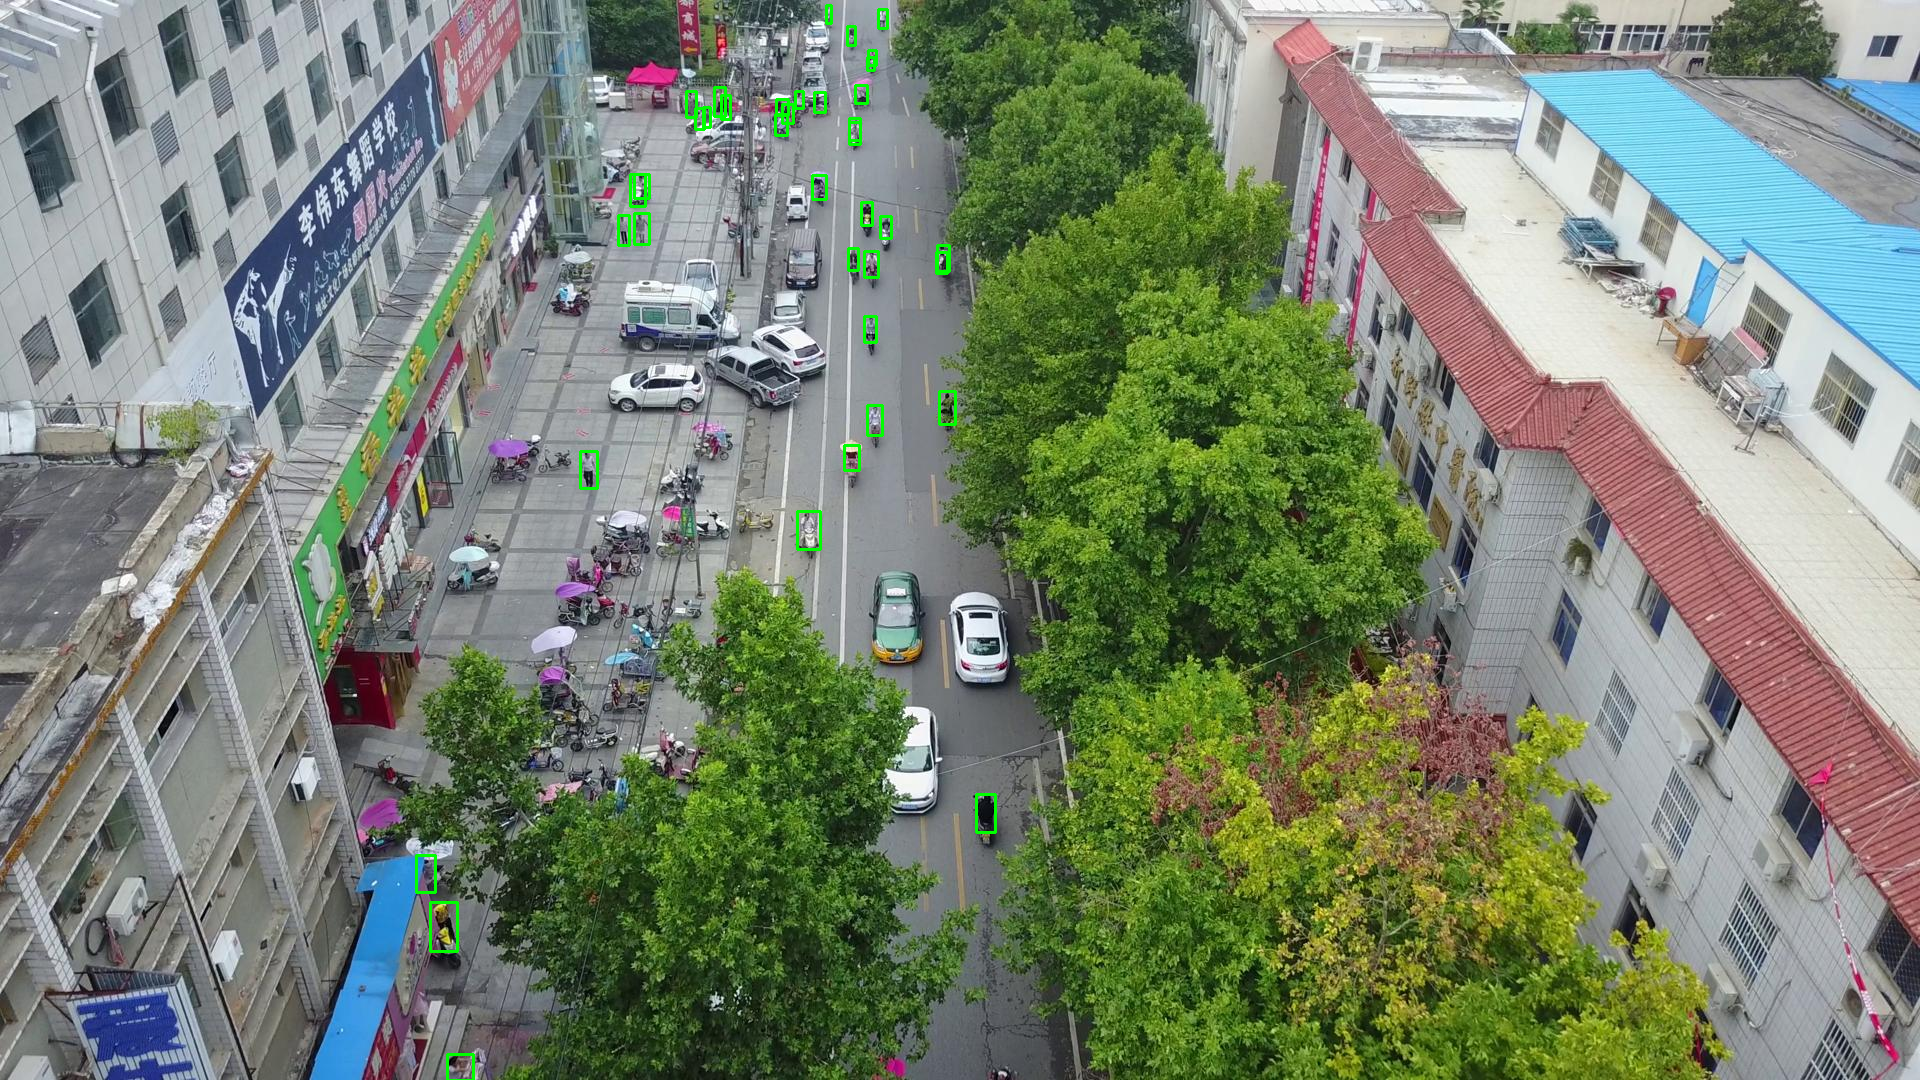

In [54]:
from google.colab.patches import cv2_imshow

path = val_image_paths[0]
image_id = Path(path).stem

image = cv2.imread(path)
H, W = image.shape[:2]

for x, y, w, h in ground_truth[image_id]:

    x1 = int((x - w/2) * W)
    y1 = int((y - h/2) * H)

    x2 = int((x + w/2) * W)
    y2 = int((y + h/2) * H)

    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

cv2_imshow(image)

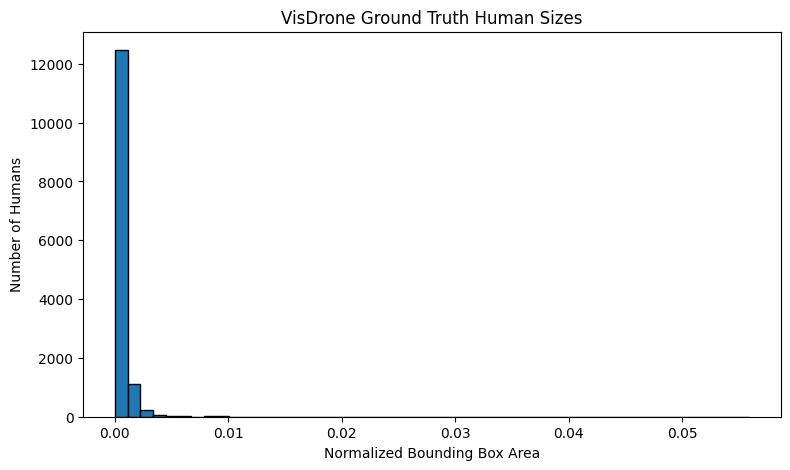

Percentage of small humans: 99.3915097716372


In [55]:
gt_areas = [
    box[2] * box[3]
    for boxes in ground_truth.values()
    for box in boxes
]

plt.figure(figsize=(9, 5))

plt.hist(gt_areas, bins=50, edgecolor="black")

plt.xlabel("Normalized Bounding Box Area")
plt.ylabel("Number of Humans")
plt.title("VisDrone Ground Truth Human Sizes")

plt.show()

print("Percentage of small humans:",
      100 * np.mean(np.array(gt_areas) < 0.005))

In [56]:
def xywh_to_xyxy(box):

    x, y, w, h = box

    return [
        x - w/2,
        y - h/2,
        x + w/2,
        y + h/2
    ]


def calculate_iou(box1, box2):

    a = xywh_to_xyxy(box1)
    b = xywh_to_xyxy(box2)

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])

    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area1 = box1[2] * box1[3]
    area2 = box2[2] * box2[3]

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [57]:
box1 = [0.5, 0.5, 0.2, 0.2]

print("Identical:",
      calculate_iou(box1, box1))

print("No overlap:",
      calculate_iou(box1, [0.9, 0.9, 0.1, 0.1]))

print("Partial overlap:",
      calculate_iou(box1, [0.6, 0.5, 0.2, 0.2]))

Identical: 0.9999999999999987
No overlap: 0.0
Partial overlap: 0.33333333333333304


In [58]:
def match_boxes(pred_boxes, gt_boxes):

    candidates = []

    for p, pred in enumerate(pred_boxes):

        for g, gt in enumerate(gt_boxes):

            iou = calculate_iou(pred, gt)

            if iou >= 0.15:
                candidates.append((iou, p, g))

    candidates.sort(reverse=True)

    used_predictions = set()
    used_ground_truth = set()

    matched_ious = []

    for iou, p, g in candidates:

        if p in used_predictions:
            continue

        if g in used_ground_truth:
            continue

        used_predictions.add(p)
        used_ground_truth.add(g)

        matched_ious.append(iou)

    return matched_ious

In [59]:
def evaluate_predictions(predictions, ground_truth,
                         conf_threshold=0.25):

    hard_tp = 0
    soft_tp = 0

    total_predictions = 0
    total_ground_truth = 0

    for image_id, gt_boxes in ground_truth.items():

        detections = predictions.get(image_id, [])

        pred_boxes = [
            box for score, box in detections
            if score >= conf_threshold
        ]

        matched_ious = match_boxes(
            pred_boxes, gt_boxes
        )

        total_predictions += len(pred_boxes)
        total_ground_truth += len(gt_boxes)

        hard_tp += sum(
            iou >= 0.30 for iou in matched_ious
        )

        soft_tp += sum(
            min(1.0, iou / 0.30)
            for iou in matched_ious
        )

    denominator = (
        total_predictions + total_ground_truth
    )

    hard_f1 = (
        2 * hard_tp / denominator
        if denominator else 0
    )

    soft_f1 = (
        2 * soft_tp / denominator
        if denominator else 0
    )

    final_score = (hard_f1 + soft_f1) / 2

    return {
        "Hard F1": hard_f1,
        "Soft F1": soft_f1,
        "Final Score": final_score,
        "Predictions": total_predictions,
        "Ground Truth": total_ground_truth
    }

In [60]:
val_predictions_640 = run_inference(
    model,
    val_image_paths,
    imgsz=640,
    conf=0.05,
    iou=0.45,
    batch_size=4
)

  0%|          | 0/137 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [61]:
val_predictions_1280 = run_inference(
    model,
    val_image_paths,
    imgsz=1280,
    conf=0.05,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/274 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [62]:
validation_comparison = pd.DataFrame({

    "E1 - 640": evaluate_predictions(
        val_predictions_640,
        ground_truth,
        conf_threshold=0.25
    ),

    "E2 - 1280": evaluate_predictions(
        val_predictions_1280,
        ground_truth,
        conf_threshold=0.25
    )
})

display(validation_comparison)

,E1 - 640,E2 - 1280
Hard F1,0.265675,0.498456
Soft F1,0.266906,0.500045
Final Score,0.266290,0.499251
Predictions,2299.000000,5142.000000
Ground Truth,13969.000000,13969.000000


In [63]:
thresholds = [
    0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40,
    0.45, 0.50
]

threshold_results = []

for conf in tqdm(thresholds):

    metrics = evaluate_predictions(
        val_predictions_1280,
        ground_truth,
        conf_threshold=conf
    )

    threshold_results.append({
        "Confidence": conf,
        **metrics
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

  0%|          | 0/10 [00:00<?, ?it/s]

,Confidence,Hard F1,Soft F1,Final Score,Predictions,Ground Truth
0,0.05,0.627178,0.634680,0.630929,10764,13969
1,0.10,0.604535,0.609314,0.606925,8124,13969
2,0.15,0.569140,0.573212,0.571176,6757,13969
3,0.20,0.533898,0.536861,0.535380,5855,13969
4,0.25,0.498456,0.500045,0.499251,5142,13969
5,0.30,0.461023,0.462252,0.461637,4529,13969
6,0.35,0.425785,0.426715,0.426250,4026,13969
7,0.40,0.386093,0.386977,0.386535,3519,13969
8,0.45,0.345107,0.345388,0.345248,3046,13969
9,0.50,0.304007,0.304295,0.304151,2603,13969


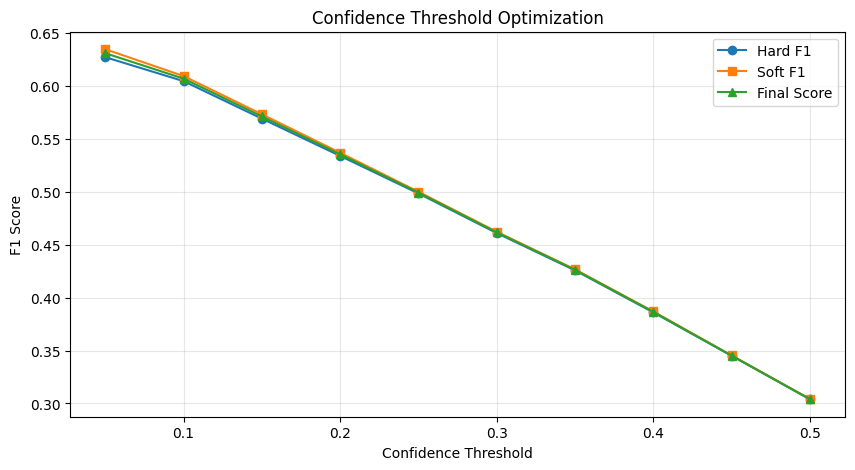

In [64]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Hard F1"],
    marker="o",
    label="Hard F1"
)

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Soft F1"],
    marker="s",
    label="Soft F1"
)

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Final Score"],
    marker="^",
    label="Final Score"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("F1 Score")
plt.title("Confidence Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [65]:
best_row = threshold_df.loc[
    threshold_df["Final Score"].idxmax()
]

best_conf = float(best_row["Confidence"])

print("Best confidence:", best_conf)
print("Best validation score:", best_row["Final Score"])

print(
    "Improvement over E2:",
    best_row["Final Score"] - 0.499251
)

Best confidence: 0.05
Best validation score: 0.6309289496384411
Improvement over E2: 0.13167794963844115


In [66]:
val_predictions_lowconf = run_inference(
    model,
    val_image_paths,
    imgsz=1280,
    conf=0.01,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/274 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [67]:
low_thresholds = [
    0.01, 0.02, 0.03,
    0.04, 0.05, 0.075, 0.10
]

low_results = []

for conf in tqdm(low_thresholds):

    metrics = evaluate_predictions(
        val_predictions_lowconf,
        ground_truth,
        conf_threshold=conf
    )

    low_results.append({
        "Confidence": conf,
        **metrics
    })

low_df = pd.DataFrame(low_results)

display(low_df)

  0%|          | 0/7 [00:00<?, ?it/s]

,Confidence,Hard F1,Soft F1,Final Score,Predictions,Ground Truth
0,0.010,0.566870,0.577775,0.572322,19873,13969
1,0.020,0.610811,0.620447,0.615629,15261,13969
2,0.030,0.625009,0.634232,0.629621,13077,13969
3,0.040,0.629158,0.637394,0.633276,11732,13969
4,0.050,0.627178,0.634680,0.630929,10764,13969
5,0.075,0.618813,0.624796,0.621804,9185,13969
6,0.100,0.604535,0.609314,0.606925,8124,13969


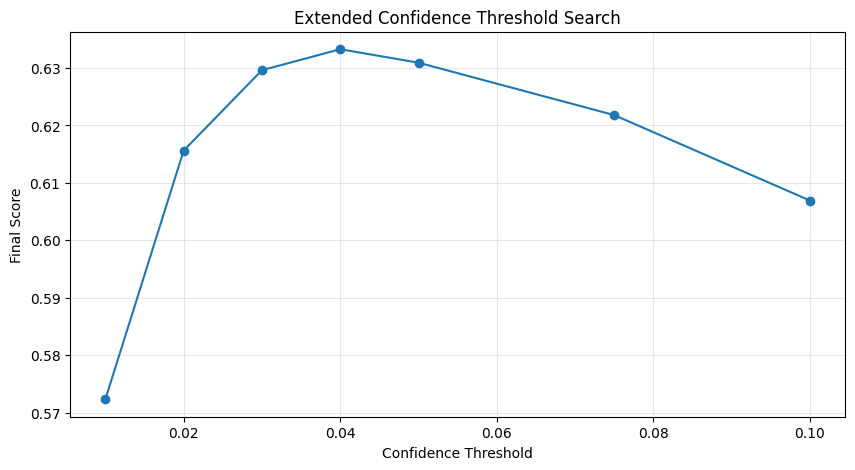

In [68]:
plt.figure(figsize=(10, 5))

plt.plot(
    low_df["Confidence"],
    low_df["Final Score"],
    marker="o"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Final Score")
plt.title("Extended Confidence Threshold Search")
plt.grid(alpha=0.3)

plt.show()

In [69]:
best_row = low_df.loc[
    low_df["Final Score"].idxmax()
]

best_conf = float(best_row["Confidence"])

print("Best Confidence:", best_conf)
print("Best Score:", best_row["Final Score"])

Best Confidence: 0.04
Best Score: 0.6332761877497725


### Confidence Threshold Analysis

The initial confidence threshold of 0.25 was found to be overly restrictive for aerial human detection on the VisDrone validation set.

Reducing the threshold to 0.05 increased the local blended F1 score from 0.49925 to 0.63093 at an input resolution of 1280 pixels.

Since the best observed score occurred at the lower boundary of the tested range, an extended threshold search was conducted to investigate whether further improvements were possible.

In [70]:
optimized_predictions = run_inference(
    model,
    image_paths,
    imgsz=1280,
    conf=best_conf,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/295 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [72]:
submission_e3 = sample[["image_id"]].copy()

submission_e3["PredictionString"] = [
    format_predictions(optimized_predictions[image_id])
    for image_id in submission_e3["image_id"]
]

submission_e3.to_csv(
    "/content/E3_optimized.csv",
    index=False
)

from google.colab import files as colab_files

colab_files.download("/content/E3_optimized.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-train.zip -O /content/visdrone_train.zip

/content/visdrone_t 100%[===================>]   1.44G  30.4MB/s    in 24s     


In [74]:
import zipfile

with zipfile.ZipFile(
    "/content/visdrone_train.zip", "r"
) as file:

    file.extractall("/content/visdrone")

In [75]:
train_dir = Path(
    "/content/visdrone/VisDrone2019-DET-train"
)

train_images = sorted(
    (train_dir / "images").glob("*.jpg")
)

train_annotations = sorted(
    (train_dir / "annotations").glob("*.txt")
)

print("Training images:", len(train_images))
print("Training annotations:", len(train_annotations))

Training images: 6471
Training annotations: 6471


In [76]:
import cv2
from tqdm.auto import tqdm

def convert_visdrone_to_yolo(dataset_dir):

    images_dir = dataset_dir / "images"
    annotations_dir = dataset_dir / "annotations"
    labels_dir = dataset_dir / "labels"

    labels_dir.mkdir(exist_ok=True)

    total_humans = 0
    empty_images = 0

    for image_path in tqdm(sorted(images_dir.glob("*.jpg"))):

        image = cv2.imread(str(image_path))
        H, W = image.shape[:2]

        annotation_path = (
            annotations_dir / f"{image_path.stem}.txt"
        )

        yolo_labels = []

        with open(annotation_path) as f:

            for line in f:

                if not line.strip():
                    continue

                values = line.strip().split(",")

                x, y, w, h = map(float, values[:4])
                score = int(values[4])
                category = int(values[5])

                if score == 0 or category not in [1, 2]:
                    continue

                x1 = max(0, x)
                y1 = max(0, y)
                x2 = min(W, x + w)
                y2 = min(H, y + h)

                if x2 <= x1 or y2 <= y1:
                    continue

                xc = (x1 + x2) / (2 * W)
                yc = (y1 + y2) / (2 * H)

                bw = (x2 - x1) / W
                bh = (y2 - y1) / H

                yolo_labels.append(
                    f"0 {xc:.6f} {yc:.6f} "
                    f"{bw:.6f} {bh:.6f}"
                )

                total_humans += 1

        if not yolo_labels:
            empty_images += 1

        label_path = labels_dir / f"{image_path.stem}.txt"

        label_path.write_text("\n".join(yolo_labels))

    print("Total humans:", total_humans)
    print("Images without labeled humans:", empty_images)

In [77]:
print("Converting training dataset...")

convert_visdrone_to_yolo(train_dir)

print("\nConverting validation dataset...")

convert_visdrone_to_yolo(val_dir)

Converting training dataset...


  0%|          | 0/6471 [00:00<?, ?it/s]

Total humans: 106396
Images without labeled humans: 787

Converting validation dataset...


  0%|          | 0/548 [00:00<?, ?it/s]

Total humans: 13969
Images without labeled humans: 17


In [78]:
import yaml

data_config = {
    "path": "/content/visdrone",

    "train": "VisDrone2019-DET-train/images",

    "val": "VisDrone2019-DET-val/images",

    "nc": 1,

    "names": {
        0: "human"
    }
}

yaml_path = "/content/visdrone/human_data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f)

print(Path(yaml_path).read_text())

names:
  0: human
nc: 1
path: /content/visdrone
train: VisDrone2019-DET-train/images
val: VisDrone2019-DET-val/images



In [79]:
!nvidia-smi

Wed Nov 25 01:23:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             32W /   70W |     869MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [80]:
import random

random.seed(42)

selected_images = random.sample(
    train_images, 2000
)

train_list_path = "/content/visdrone/train_subset.txt"

with open(train_list_path, "w") as f:
    f.write("\n".join(
        str(p) for p in selected_images
    ))

print("Selected training images:", len(selected_images))

Selected training images: 2000


In [81]:
subset_config = data_config.copy()

subset_config["train"] = train_list_path

subset_yaml = "/content/visdrone/human_subset.yaml"

with open(subset_yaml, "w") as f:
    yaml.safe_dump(subset_config, f)

print(Path(subset_yaml).read_text())

names:
  0: human
nc: 1
path: /content/visdrone
train: /content/visdrone/train_subset.txt
val: VisDrone2019-DET-val/images



In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

aerial_model = YOLO("yolo11m.pt")

training_results = aerial_model.train(

    data=subset_yaml,

    epochs=10,
    time=1.0,

    imgsz=960,
    batch=4,
    device=0,
    amp=True,

    degrees=180,
    fliplr=0.5,
    flipud=0.5,

    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.4,

    scale=0.5,
    translate=0.1,

    mosaic=0.5,
    mixup=0.0,
    close_mosaic=2,

    optimizer="AdamW",
    lr0=0.001,

    workers=2,
    cache=False,

    seed=42,
    patience=5,

    save=True,
    save_period=1,
    plots=True,

    project="/content/experiments",
    name="E4_aerial_finetuning"
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/visdrone/human_subset.yaml, degrees=180, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=E4_aerial_finetuning, nbs=64, nms=None, opset=None, o

In [1]:
from pathlib import Path

print("Dataset exists:",
      Path("/content/visdrone").exists())

print("Saved checkpoints:")

for p in Path("/content/experiments").rglob("*.pt"):
    print(p)

Dataset exists: True
Saved checkpoints:


In [2]:
import torch
import gc
from pathlib import Path
from ultralytics import YOLO

gc.collect()
torch.cuda.empty_cache()

subset_yaml = "/content/visdrone/human_subset.yaml"

print("GPU available:", torch.cuda.is_available())
print("YAML exists:", Path(subset_yaml).exists())
print("Pretrained weights exist:", Path("/content/yolo11m.pt").exists())

GPU available: True
YAML exists: True
Pretrained weights exist: True


In [ ]:
aerial_model = YOLO("yolo11m.pt")

training_results = aerial_model.train(

    data=subset_yaml,

    epochs=10,

    imgsz=960,
    batch=2,
    device=0,
    amp=True,

    degrees=180,
    fliplr=0.5,
    flipud=0.5,

    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.4,

    scale=0.5,
    translate=0.1,

    mosaic=0.5,
    mixup=0.0,
    close_mosaic=2,

    optimizer="AdamW",
    lr0=0.001,

    workers=0,
    cache=False,

    seed=42,
    patience=5,

    save=True,
    save_period=1,
    plots=False,

    project="/content/experiments",
    name="E4_aerial_lowram"
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/visdrone/human_subset.yaml, degrees=180, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=E4_aerial_lowram, nbs=64, nms=None, opset=None, optim